<a href="https://colab.research.google.com/github/smartypants85/SCUDEM-Hill-Model-RK4/blob/advanced_fit/fit_growth_strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

AGE0, DT, G = 5.0, 0.25, 9.81
AGES = np.arange(5, 15)  # strength data: ages 5..14

# NHANES 2021-2023 Table 17, upper arm length, 50th percentile (cm). Band midpoints.
UAL_AGES = np.array([5.0, 7.0, 9.0, 11.0, 13.0, 15.0, 17.0, 19.0, 24.5])  # last = adults 20-29 (Table 18)
UAL_CM = {
    "boys":  np.array([22.5, 26.0, 28.7, 31.8, 35.5, 37.9, 38.9, 38.5, 39.4]),
    "girls": np.array([22.3, 25.5, 28.1, 32.0, 34.2, 35.0, 35.4, 35.4, 35.9]),
}
# Table 18, adults 20-29, 50th percentile (cm) -- same numbers as the last point above
ADULT_CHECK = {"boys": 39.4, "girls": 35.9}

# Daloia 2018 Appendix A, elbow flexors, dominant side, kgf, ages 5..14
STRENGTH_KGF = {
    "boys":  [6.59, 7.35, 9.14, 9.60, 9.88, 10.83, 11.97, 12.84, 14.22, 18.19],
    "girls": [7.35, 8.36, 7.68, 9.24, 10.01, 9.79, 9.01, 11.39, 12.16, 12.96],
}

# Geometry from your sheet (age_0 values)
H0, DR0 = 0.24, 0.03
FOREARM_OVER_UPPERARM = 0.785  # forearm / upper-arm length (Drillis & Contini: 0.146H / 0.186H)


def lam_euler(k, linf, t_end=25.0):
    n = int(round((t_end - AGE0) / DT))
    lam = np.empty(n + 1)
    lam[0] = 1.0
    for i in range(n):
        lam[i + 1] = lam[i] + DT * k * lam[i] * (1 - lam[i] / linf)
    return lam


def lam_at(ages, k, linf):
    lam = lam_euler(k, linf)
    idx = np.round((np.asarray(ages) - AGE0) / DT).astype(int)
    return lam[idx]


def fit_growth(ages, y):
    def f(a, k, linf, a5):
        return a5 * lam_at(a, k, linf)
    popt, pcov = curve_fit(f, ages, y, p0=[0.2, 1.6, y[0]],
                           bounds=([0.01, 1.05, 15.0], [2.0, 3.0, 30.0]))
    return popt, np.sqrt(np.diag(pcov)), f


def fit_force(k, linf, ual5_m, kgf):
    a_arm = H0 * DR0 / np.sqrt(H0**2 + DR0**2)       # biceps moment arm at age_0
    L_fa0 = FOREARM_OVER_UPPERARM * ual5_m            # lever arm to wrist at age_0
    r = a_arm / L_fa0                                 # F_wrist = r * F_muscle (both scale with lambda)

    def f(a, F0):
        return F0 * lam_at(a, k, linf) ** 2 * r / G
    popt, pcov = curve_fit(f, AGES, kgf, p0=[300.0])
    return popt[0], float(np.sqrt(pcov[0, 0])), r, f


if __name__ == "__main__":
    results = {}
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for j, sex in enumerate(["boys", "girls"]):
        y = UAL_CM[sex]
        (k, linf, a5), (ek, el, ea), fg = fit_growth(UAL_AGES, y)
        rmse_h = np.sqrt(np.mean((fg(UAL_AGES, k, linf, a5) - y) ** 2))
        F0, eF0, r, ff = fit_force(k, linf, a5 / 100, np.array(STRENGTH_KGF[sex]))
        pred = ff(AGES, F0)
        rmse_f = np.sqrt(np.mean((pred - np.array(STRENGTH_KGF[sex])) ** 2))
        ceiling = a5 * linf
        results[sex] = dict(k=k, ek=ek, linf=linf, el=el, ual5_cm=a5, F0=F0, eF0=eF0, r=r,
                            rmse_arm_cm=rmse_h, rmse_force_kgf=rmse_f, F_adult=F0 * linf ** 2)
        print(f"\n=== {sex} ===")
        print(f"k        = {k:.4f} +/- {ek:.4f}   (sheet: 0.22)")
        print(f"lam_inf  = {linf:.4f} +/- {el:.4f}   (sheet: 1.55)")
        print(f"arm(5)   = {a5:.2f} cm; fitted adult arm = {ceiling:.1f} cm vs NHANES adult 20-29 = "
              f"{ADULT_CHECK[sex]} cm;  arm RMSE = {rmse_h:.2f} cm")
        print(f"F_max0   = {F0:.1f} +/- {eF0:.1f} N   (sheet: 300)   moment-arm ratio r = {r:.3f}")
        print(f"strength RMSE = {rmse_f:.2f} kgf;  implied adult F_max = F_max0*lam_inf^2 = {F0*linf**2:.0f} N")

        tt = np.linspace(5, 25, 81)
        ax = axes[0, j]
        ax.scatter(UAL_AGES, y, label="NHANES median upper arm length (last pt = adults)")
        ax.plot(tt, a5 * lam_at(tt, k, linf), "r", label="logistic fit (k, lam_inf)")
        ax.set(title=f"{sex}: arm length", xlabel="age (yr)", ylabel="upper arm length (cm)"); ax.legend(fontsize=8)
        ax = axes[1, j]
        ax.scatter(AGES, STRENGTH_KGF[sex], label="data (kgf at wrist)")
        t2 = tt[tt <= 14.01]
        ax.plot(t2, ff(t2, F0), "r", label="F_max0*lam^2 fit")
        ax.set(title=f"{sex}: elbow flexion force", xlabel="age (yr)", ylabel="kgf"); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig("growth_strength_fit.png", dpi=130)
    pd.DataFrame(results).T.to_csv("fitted_params.csv")
    print("\nSaved growth_strength_fit.png and fitted_params.csv")



=== boys ===
k        = 0.2069 +/- 0.0257   (sheet: 0.22)
lam_inf  = 1.8575 +/- 0.0626   (sheet: 1.55)
arm(5)   = 21.90 cm; fitted adult arm = 40.7 cm vs NHANES adult 20-29 = 39.4 cm;  arm RMSE = 0.73 cm
F_max0   = 328.8 +/- 10.5 N   (sheet: 300)   moment-arm ratio r = 0.173
strength RMSE = 1.10 kgf;  implied adult F_max = F_max0*lam_inf^2 = 1134 N

=== girls ===
k        = 0.2460 +/- 0.0275   (sheet: 0.22)
lam_inf  = 1.6760 +/- 0.0453   (sheet: 1.55)
arm(5)   = 21.76 cm; fitted adult arm = 36.5 cm vs NHANES adult 20-29 = 35.9 cm;  arm RMSE = 0.55 cm
F_max0   = 296.1 +/- 12.1 N   (sheet: 300)   moment-arm ratio r = 0.174
strength RMSE = 1.21 kgf;  implied adult F_max = F_max0*lam_inf^2 = 832 N

Saved growth_strength_fit.png and fitted_params.csv


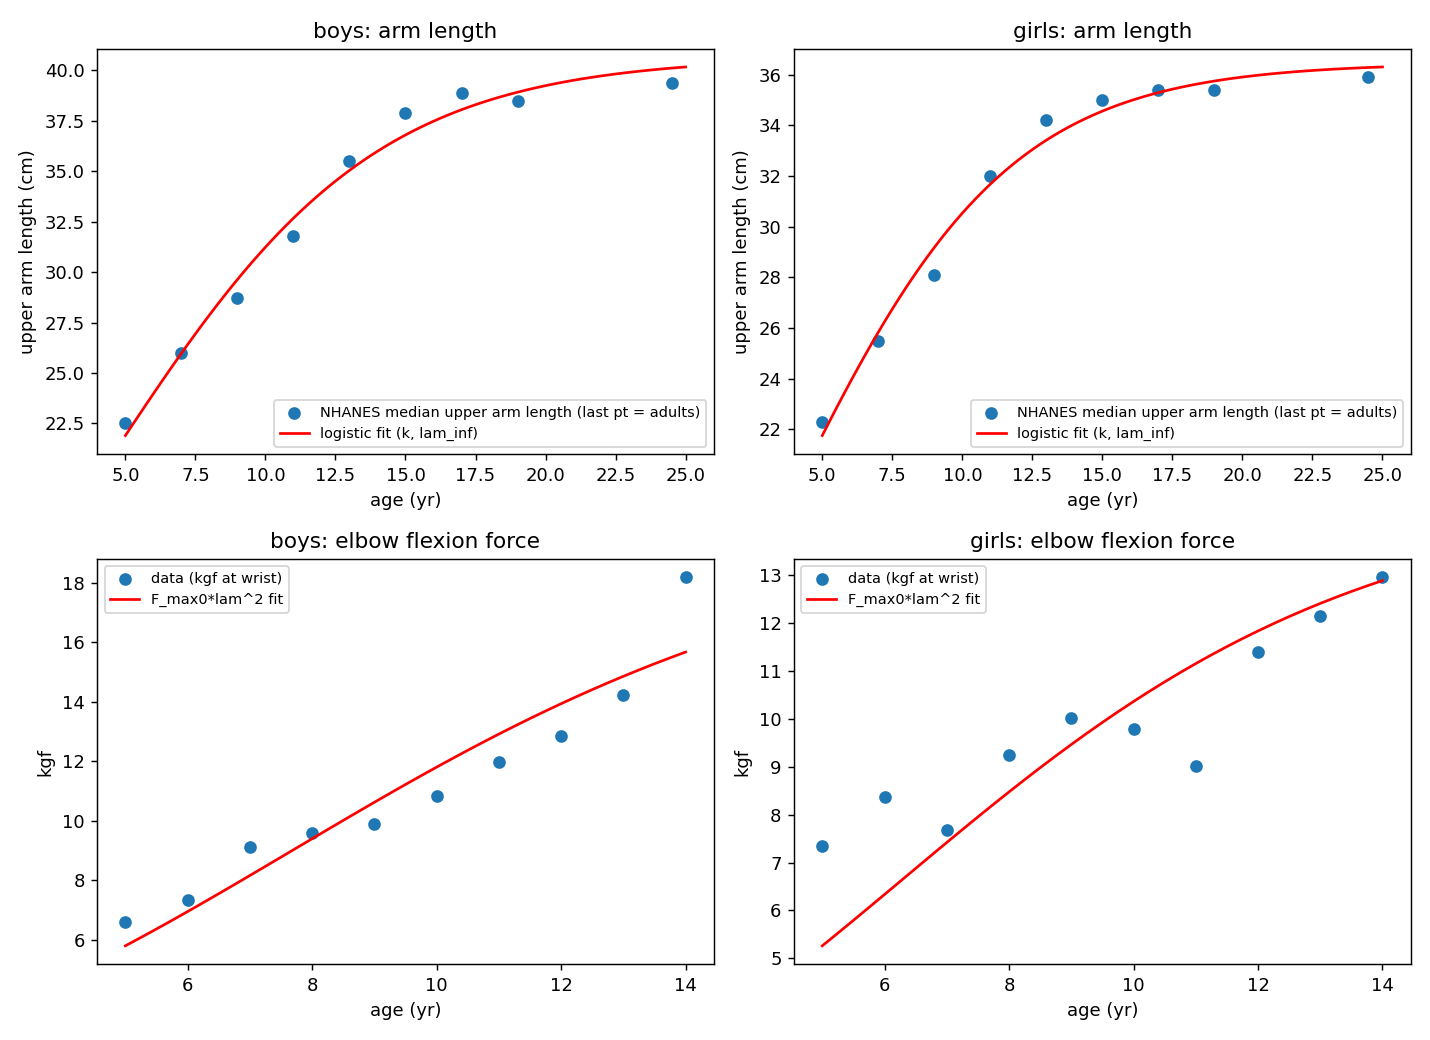

In [ ]:
from IPython.display import Image
Image('growth_strength_fit.png')
